<a href="https://colab.research.google.com/github/nurtuasikal-cmyk/Project-UTS-Kelompok-7/blob/main/Jurnal_UAS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><center> JURNAL UAS </center></h1>
Kelompok 7


In [ ]:
#PACKAAGE
#package PythonTsa
!pip install PythonTsa

# menginstall package pydataset
!pip install pydataset

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 441.1/441.1 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 30.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pydataset: filename=pydataset-0.2.0-py3-none-any.whl size=15939458 sha256=dcca8df4e647fdf6b4aed7a89138ed6c24a0ff1c317ac21ddf6a9cb27f0e9d0b
  Stored in directory: /root/.cache/pip/wheels/49/2a/45/180e1199b8d925b5c43df8f9850dcc2e5dfc94e3e99a55b83e
Successfully built pydataset


In [1]:
#memanggil packages yang dibutuhkan
import numpy as np
import pandas as pd
import math
import random
import matplotlib.pyplot as plt
import seaborn as sns
import re
from google.colab import files

import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd

link = "https://github.com/nurtuasikal-cmyk/Project-UTS-Kelompok-7/raw/d49a24f89b30e754e6b410f742d5bbf22da15802/Data.xlsx"

# cek nama sheet dulu
print(pd.ExcelFile(link).sheet_names)

nao = pd.read_excel(link, sheet_name=0)   # atau sheet_name="DATA ADW" jika namanya itu
nao.head()

['DATA ADW']


,Provinsi,Tahun,Bulan,Produksi Padi (Y),Luas Panen (X1),Produkitivitas (X2)
0,ACEH,2018,Januari,76118.47,14541.53,52.345572
1,ACEH,2018,Februari,142876.76,27075.77,52.769232
2,ACEH,2018,Maret,375841.91,66403.96,56.599322
3,ACEH,2018,April,336742.80,58507.03,57.555955
4,ACEH,2018,Mei,96372.36,16867.65,57.134432


In [3]:
# melihat struktur data
nao.dtypes

,0
Provinsi,object
Tahun,int64
Bulan,object
Produksi Padi (Y),float64
Luas Panen (X1),float64
Produkitivitas (X2),float64


In [4]:
# %% [markdown]
# # Analisis Deret Waktu: EDA dan Pembagian Data
#
# Lanjutan dari cell [1], [2], dan [4] (impor package dan pembacaan data `nao`).

# %%
# package tambahan untuk analisis deret waktu
from scipy import stats
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.model_selection import TimeSeriesSplit

plt.rcParams["figure.figsize"] = (11, 4)
pd.options.display.float_format = "{:,.2f}".format

In [5]:
# %% [markdown]
# ## A. IMPOR & PEMBERSIHAN

# %%
raw = nao.copy()      # data dari cell [4]
raw.columns = ["provinsi", "tahun", "bulan", "Y", "X1", "X2"]   # Y = Produksi Padi

peta_bulan = {"Januari": 1, "Februari": 2, "Maret": 3, "April": 4, "Mei": 5,
              "Juni": 6, "Juli": 7, "Agustus": 8, "September": 9,
              "Oktober": 10, "Nopember": 11, "November": 11, "Desember": 12}

dat = raw.copy()
dat["bulan"] = dat["bulan"].str.strip()          # ada spasi, mis. "Oktober "
dat["bln"] = dat["bulan"].map(peta_bulan)
print("Bulan tidak terpetakan:", dat["bln"].isna().sum())   # harus 0
dat["tgl"] = pd.to_datetime(dict(year=dat["tahun"], month=dat["bln"], day=1))
dat = dat.sort_values(["provinsi", "tgl"]).reset_index(drop=True)

dat.head()

Bulan tidak terpetakan: 0


,provinsi,tahun,bulan,Y,X1,X2,bln,tgl
0,ACEH,2018,Januari,"76,118.47","14,541.53",52.35,1,2018-01-01
1,ACEH,2018,Februari,"142,876.76","27,075.77",52.77,2,2018-02-01
2,ACEH,2018,Maret,"375,841.91","66,403.96",56.60,3,2018-03-01
3,ACEH,2018,April,"336,742.80","58,507.03",57.56,4,2018-04-01
4,ACEH,2018,Mei,"96,372.36","16,867.65",57.13,5,2018-05-01


In [6]:
# %% [markdown]
# ## B. STRUKTUR & KUALITAS DATA

# %%
dat.info()
print("\nMissing per kolom:\n", dat.isna().sum())
print("\nDuplikat provinsi-bulan:", dat.duplicated(["provinsi", "tgl"]).sum())   # harus 0
print("\nJumlah provinsi:", dat["provinsi"].nunique())
print("Periode:", dat["tgl"].min().strftime("%b %Y"), "-", dat["tgl"].max().strftime("%b %Y"))
print("\nJumlah bulan per provinsi:\n", dat.groupby("provinsi").size().value_counts())

# provinsi dengan produksi bernilai 0
nol = dat[dat["Y"] == 0].groupby("provinsi").size().sort_values(ascending=False)
print("\nBaris dengan Y = 0 per provinsi:\n", nol)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3952 entries, 0 to 3951
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   provinsi  3952 non-null   object        
 1   tahun     3952 non-null   int64         
 2   bulan     3952 non-null   object        
 3   Y         3952 non-null   float64       
 4   X1        3952 non-null   float64       
 5   X2        3771 non-null   float64       
 6   bln       3952 non-null   int64         
 7   tgl       3952 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), int64(2), object(2)
memory usage: 247.1+ KB

Missing per kolom:
 provinsi      0
tahun         0
bulan         0
Y             0
X1            0
X2          181
bln           0
tgl           0
dtype: int64

Duplikat provinsi-bulan: 0

Jumlah provinsi: 38
Periode: Jan 2018 - Aug 2026

Jumlah bulan per provinsi:
 104    38
Name: count, dtype: int64

Baris dengan Y = 0 per provinsi:
 provinsi
PA

In [7]:
# %% [markdown]
# ## C. MEMBENTUK DERET WAKTU

# %%
LEVEL = "Nasional"      # "Nasional" (jumlah semua provinsi) atau satu provinsi, mis. "JAWA BARAT"
NAMA = "Produksi Padi"

if LEVEL == "Nasional":
    y = dat.groupby("tgl")["Y"].sum()
else:
    y = dat.loc[dat["provinsi"] == LEVEL].set_index("tgl")["Y"]

y.index = pd.DatetimeIndex(y.index, freq="MS")      # frekuensi bulanan
y.name = NAMA
print(f"Deret '{LEVEL}': {len(y)} bulan, {y.index[0]:%b %Y} - {y.index[-1]:%b %Y}")
y.head(12)

Deret 'Nasional': 104 bulan, Jan 2018 - Aug 2026


,Produksi Padi
tgl,
2018-01-01,"2,783,961.29"
2018-02-01,"5,738,544.13"
2018-03-01,"9,678,183.21"
2018-04-01,"7,603,154.96"
2018-05-01,"4,901,168.61"
2018-06-01,"4,490,437.99"
2018-07-01,"5,434,002.45"
2018-08-01,"5,372,659.71"
2018-09-01,"5,184,048.98"


count         104.00
mean    4,700,388.73
std     2,106,002.37
min     1,516,039.96
25%     3,246,217.89
50%     4,347,959.12
75%     5,494,256.53
max     9,768,002.01
Name: Produksi Padi, dtype: float64

Koefisien variasi (%): 44.8


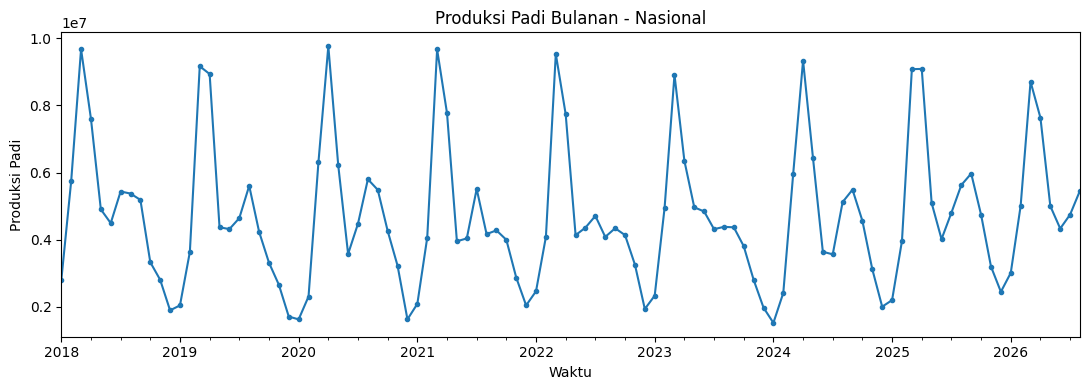

In [8]:
# %% [markdown]
# ## D. EDA

# %% [markdown]
# ### D1. Ringkasan statistik dan plot deret waktu

# %%
print(y.describe())
print(f"\nKoefisien variasi (%): {y.std() / y.mean() * 100:.1f}")

fig, ax = plt.subplots()
y.plot(ax=ax, marker="o", ms=3)
ax.set(title=f"{NAMA} Bulanan - {LEVEL}", xlabel="Waktu", ylabel=NAMA)
plt.tight_layout()
plt.show()

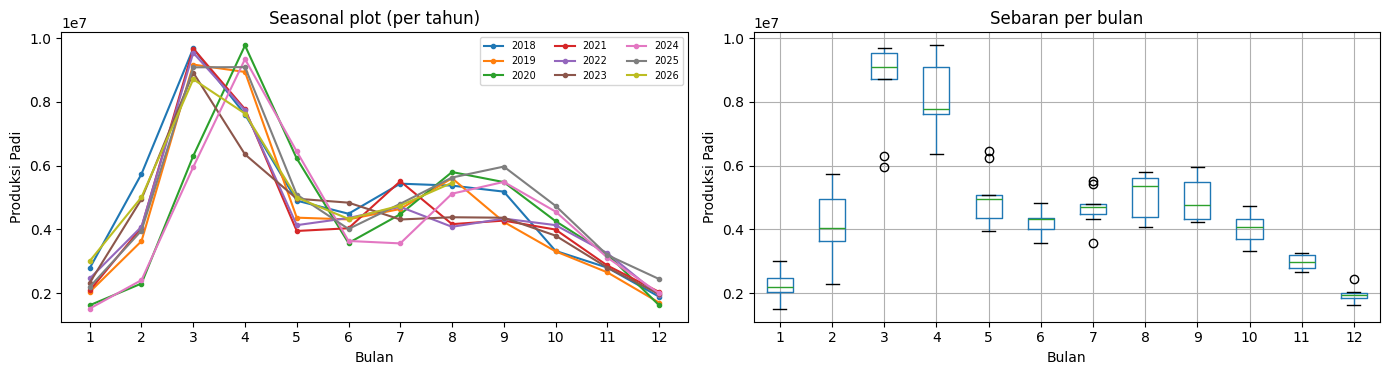

In [9]:
# %% [markdown]
# ### D2. Pola musiman

# %%
tabel = y.to_frame("Y").assign(tahun=y.index.year, bln=y.index.month)
pivot = tabel.pivot(index="bln", columns="tahun", values="Y")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pivot.plot(ax=axes[0], marker="o", ms=3)                  # seasonal plot
axes[0].set(title="Seasonal plot (per tahun)", xlabel="Bulan", ylabel=NAMA)
axes[0].set_xticks(range(1, 13))
axes[0].legend(ncol=3, fontsize=7)

tabel.boxplot(column="Y", by="bln", ax=axes[1])           # sebaran per bulan
axes[1].set(title="Sebaran per bulan", xlabel="Bulan", ylabel=NAMA)
fig.suptitle("")
plt.tight_layout()
plt.show()

**Berdasarkan plot deret waktu yang dihasilkan apa yang dapat Anda interpretasikan?**
<div align="justify">(ADF).
</div>

             mean  count
tgl                     
2018 4,933,377.81     12
2019 4,550,336.11     12
2020 4,554,100.19     12
2021 4,534,607.85     12
2022 4,562,414.76     12
2023 4,498,416.10     12
2024 4,428,560.55     12
2025 5,017,258.38     12
2026 5,486,445.85      8


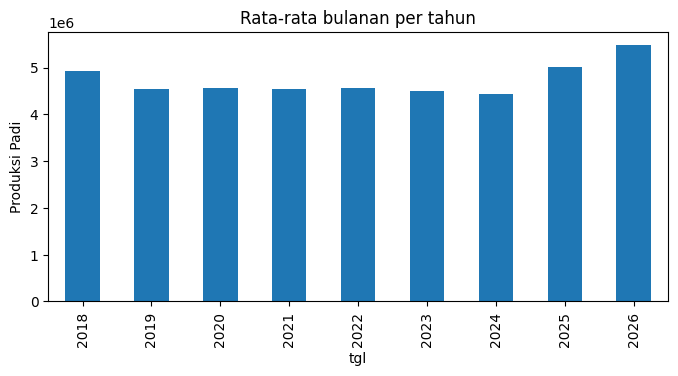

In [10]:
# ### D3. Rata-rata tahunan (melihat tren)

# %%
# tahun terakhir mungkin belum lengkap 12 bulan
rata = y.groupby(y.index.year).agg(["mean", "count"])
print(rata)

rata["mean"].plot(kind="bar", figsize=(8, 3.5), title="Rata-rata bulanan per tahun")
plt.ylabel(NAMA)
plt.show()

**Apa yang dapat Anda maknai dari scatterplot tersebut?**
<div align="justify"> .</div>

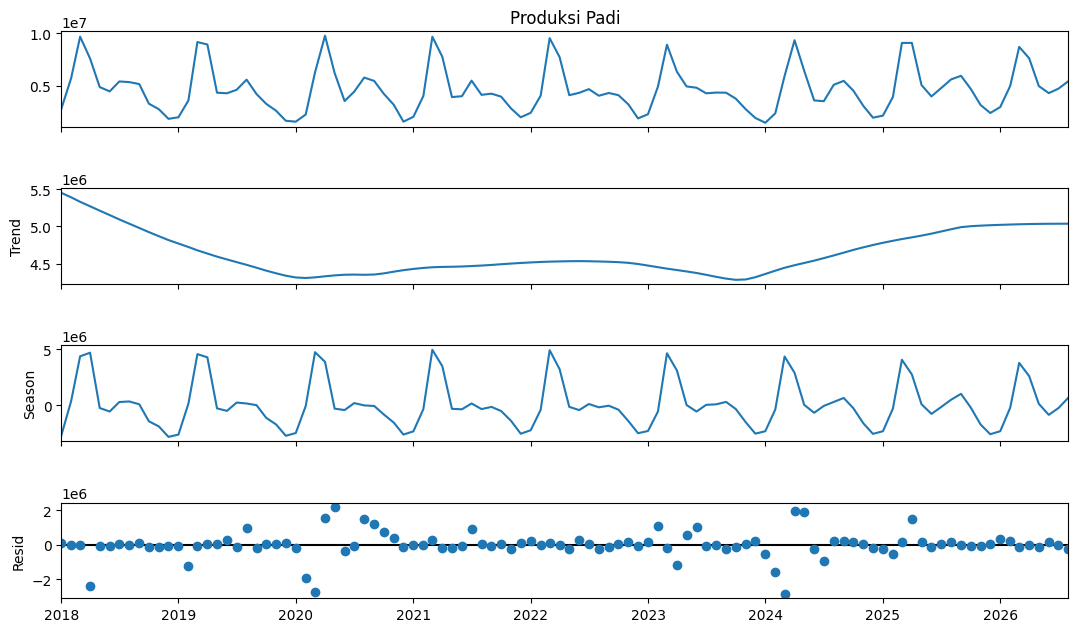

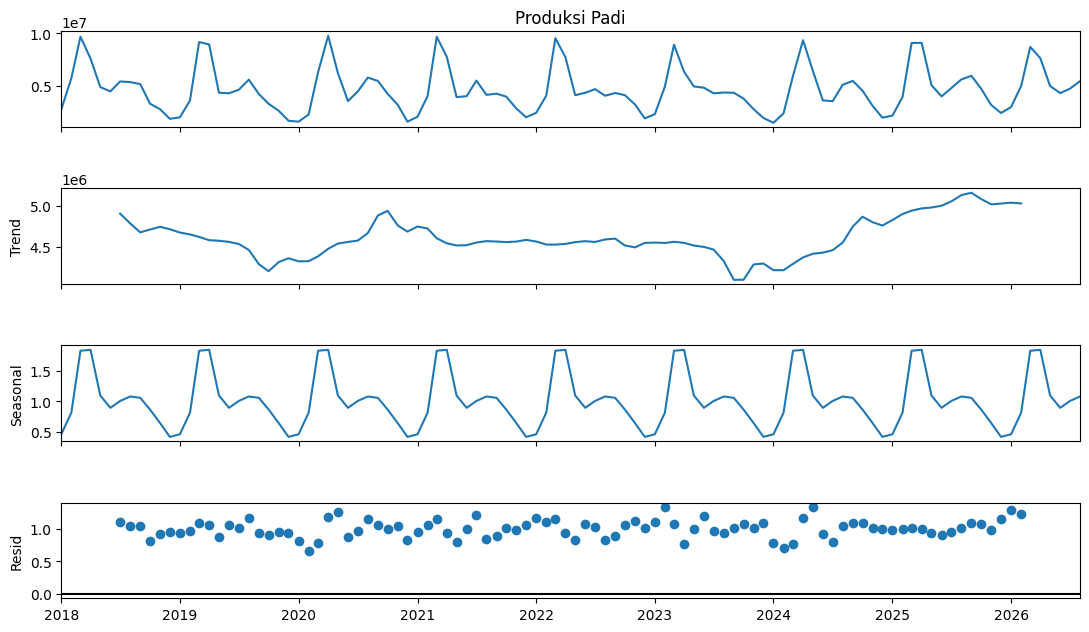

In [11]:
#%% [markdown]
# ### D4. Dekomposisi

# %%
# STL (robust terhadap outlier)
stl = STL(y, period=12, robust=True).fit()
stl.plot()
plt.gcf().set_size_inches(11, 7)
plt.show()

# dekomposisi klasik multiplikatif (butuh semua nilai > 0)
if (y > 0).all():
    dek = seasonal_decompose(y, model="multiplicative", period=12)
    dek.plot()
    plt.gcf().set_size_inches(11, 7)
    plt.show()
else:
    print("Dekomposisi multiplikatif dilewati: ada nilai <= 0")

In [12]:
# ### D5. Deteksi outlier

# %%
# residual STL di luar batas 1.5 x IQR
res = stl.resid
q1, q3 = res.quantile([0.25, 0.75])
batas = 1.5 * (q3 - q1)
outlier = y[(res < q1 - batas) | (res > q3 + batas)]
print("Kandidat outlier:")
print(outlier)

Kandidat outlier:
tgl
2018-04-01   7,603,154.96
2019-02-01   3,631,559.37
2019-08-01   5,603,864.74
2020-02-01   2,302,274.86
2020-03-01   6,302,865.34
2020-04-01   9,768,002.01
2020-05-01   6,223,452.84
2020-08-01   5,798,746.50
2020-09-01   5,483,198.85
2020-10-01   4,259,352.80
2021-07-01   5,510,292.14
2023-02-01   4,949,750.92
2023-04-01   6,351,759.64
2023-06-01   4,838,112.69
2024-02-01   2,409,079.63
2024-03-01   5,955,666.80
2024-04-01   9,340,067.77
2024-05-01   6,443,243.14
2024-07-01   3,560,388.25
2025-04-01   9,089,488.11
Name: Produksi Padi, dtype: float64


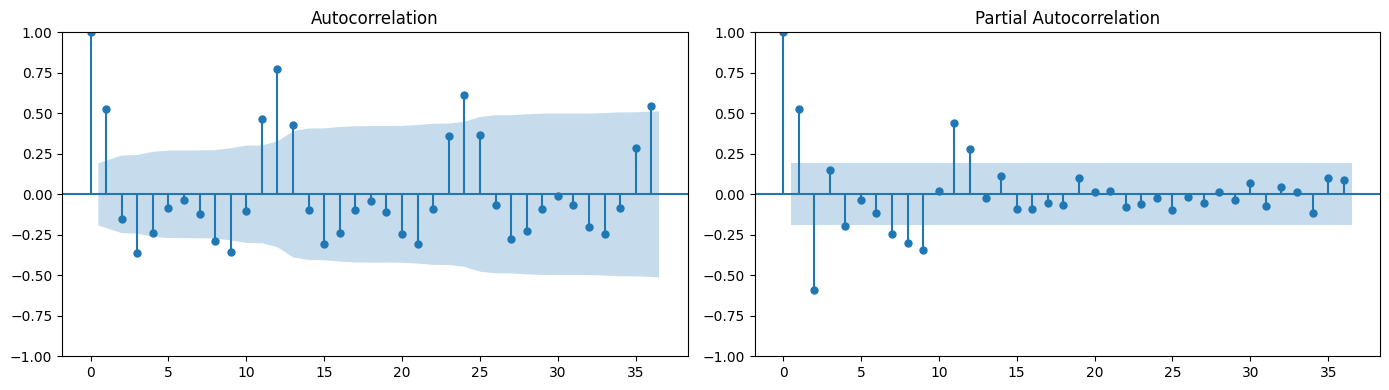

In [13]:
# ## E. UJI AWAL KESTASIONERAN (Tahap 1 Box-Jenkins)

# %% [markdown]
# ### E1. ACF dan PACF data asli
# ACF yang turun lambat menandakan data tidak stasioner dalam rata-rata.

# %%
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y, lags=36, ax=axes[0])
plot_pacf(y, lags=36, ax=axes[1], method="ywm")
plt.tight_layout()
plt.show()

In [14]:
# ### E2. Uji ADF
# p-value < 0,05 berarti stasioner dalam rata-rata.

# %%
def adf(x, judul):
    stat, p, lag, n, kritis, _ = adfuller(x.dropna(), autolag="AIC")
    print(f"ADF {judul:<26} stat={stat:8.3f}  p-value={p:.4f}  lag={lag}  -> "
          f"{'stasioner' if p < 0.05 else 'TIDAK stasioner'}")

adf(y, "data asli")
adf(y.diff(), "diferensiasi d=1")
adf(y.diff(12), "diferensiasi musiman D=1")
adf(y.diff(12).diff(), "D=1 dan d=1")

ADF data asli                  stat=  -0.819  p-value=0.8134  lag=13  -> TIDAK stasioner
ADF diferensiasi d=1           stat=  -8.132  p-value=0.0000  lag=12  -> stasioner
ADF diferensiasi musiman D=1   stat=  -5.697  p-value=0.0000  lag=2  -> stasioner
ADF D=1 dan d=1                stat=  -3.903  p-value=0.0020  lag=11  -> stasioner


In [15]:
# ### E3. Box-Cox dan saran orde diferensiasi

# %%
# Box-Cox: lambda mendekati 1 -> tanpa transformasi, mendekati 0 -> log
if (y > 0).all():
    lam = stats.boxcox_normmax(y.values, method="mle")
    print(f"Lambda Box-Cox (MLE): {lam:.3f}")
else:
    print("Box-Cox dilewati: ada nilai <= 0 pada deret")

# saran d (diferensiasi non-musiman) lewat ADF berulang
d, x = 0, y.copy()
while adfuller(x.dropna())[1] >= 0.05 and d < 2:
    x = x.diff()
    d += 1

Lambda Box-Cox (MLE): 0.177


In [16]:
# saran D (diferensiasi musiman) lewat kekuatan musiman
Fs = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())
D = int(Fs > 0.64)
print(f"Saran awal: d = {d}, D = {D}  (kekuatan musiman Fs = {Fs:.2f})")

Saran awal: d = 1, D = 1  (kekuatan musiman Fs = 0.87)


Train: 92 bulan (Jan 2018 - Aug 2025)
Test : 12 bulan (Sep 2025 - Aug 2026)


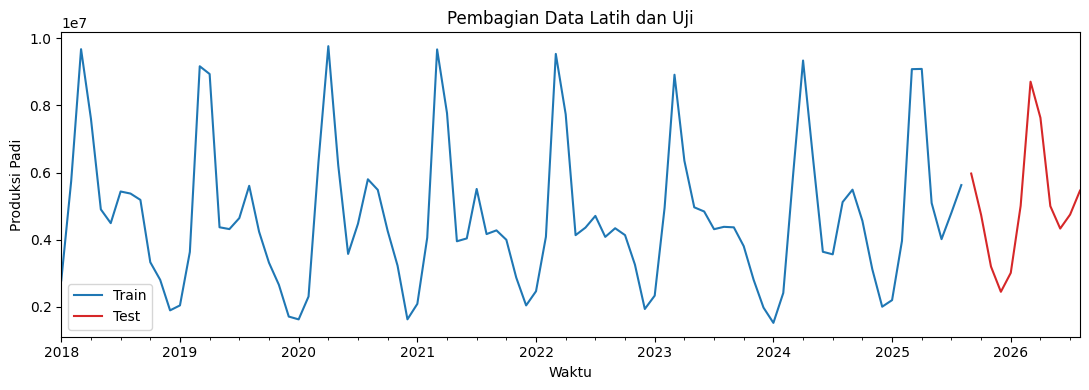

In [17]:
# ## F. PEMBAGIAN DATA (TRAIN - TEST)
# Data deret waktu dibagi secara **berurutan**, tidak diacak.

# %%
H_TEST = 12                       # test = 12 bulan terakhir (1 siklus musiman)
n = len(y)
n_train = n - H_TEST              # alternatif 80:20 -> int(0.8 * n)

y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]
print(f"Train: {len(y_train)} bulan ({y_train.index[0]:%b %Y} - {y_train.index[-1]:%b %Y})")
print(f"Test : {len(y_test)} bulan ({y_test.index[0]:%b %Y} - {y_test.index[-1]:%b %Y})")

fig, ax = plt.subplots()
y_train.plot(ax=ax, label="Train")
y_test.plot(ax=ax, label="Test", color="tab:red")
ax.set(title="Pembagian Data Latih dan Uji", xlabel="Waktu", ylabel=NAMA)
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
# Transformasi, diferensiasi, dan estimasi parameter hanya memakai y_train.

# %%
# expanding window (time series cross-validation) pada data train
tscv = TimeSeriesSplit(n_splits=5, test_size=H_TEST)
for i, (tr, te) in enumerate(tscv.split(y_train), 1):
    print(f"Lipatan {i}: train {y_train.index[tr[0]]:%b %Y} - {y_train.index[tr[-1]]:%b %Y} ({len(tr)} bln) | "
          f"validasi {y_train.index[te[0]]:%b %Y} - {y_train.index[te[-1]]:%b %Y}")

Lipatan 1: train Jan 2018 - Aug 2020 (32 bln) | validasi Sep 2020 - Aug 2021
Lipatan 2: train Jan 2018 - Aug 2021 (44 bln) | validasi Sep 2021 - Aug 2022
Lipatan 3: train Jan 2018 - Aug 2022 (56 bln) | validasi Sep 2022 - Aug 2023
Lipatan 4: train Jan 2018 - Aug 2023 (68 bln) | validasi Sep 2023 - Aug 2024
Lipatan 5: train Jan 2018 - Aug 2024 (80 bln) | validasi Sep 2024 - Aug 2025


                                     SARIMAX Results                                      
Dep. Variable:                      Produksi Padi   No. Observations:                   92
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood               -1029.035
Date:                            Wed, 14 Oct 2026   AIC                           2068.071
Time:                                    13:49:51   BIC                           2079.918
Sample:                                01-01-2018   HQIC                          2072.817
                                     - 08-01-2025                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
X1             5.2463      0.057     92.101      0.000       5.135       5.358
ar.L1          0.3612      0.149   

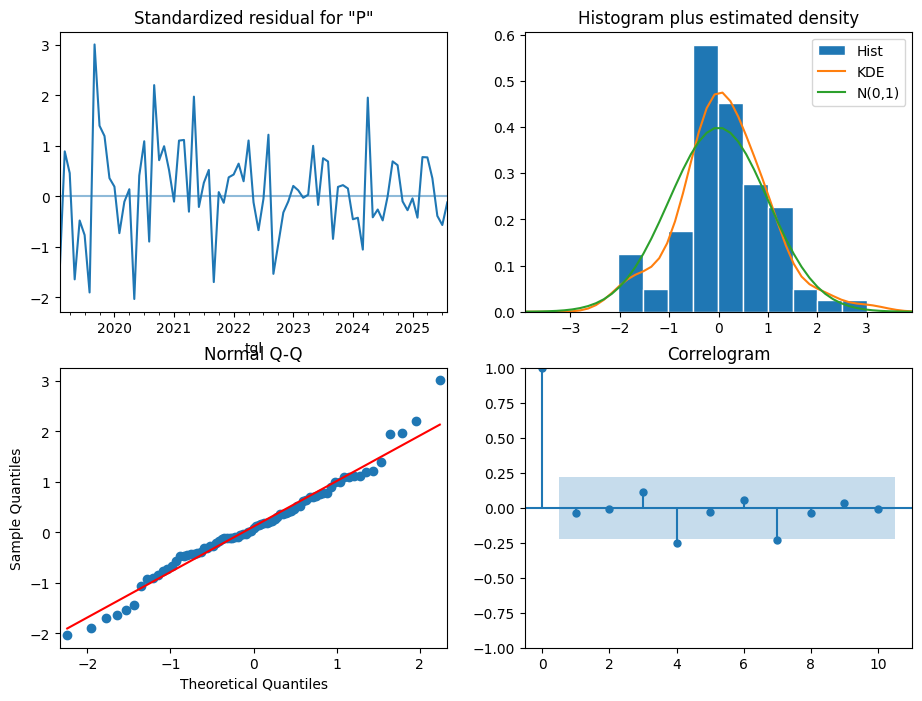

In [19]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# X nasional = jumlah luas panen seluruh provinsi
X = dat.groupby("tgl")[["X1"]].sum()
X.index = pd.DatetimeIndex(X.index, freq="MS")
X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]

# contoh model awal; ordenya ganti sesuai ACF/PACF data terdiferensiasi
mod = SARIMAX(y_train, exog=X_train,
              order=(1, d, 1), seasonal_order=(0, D, 1, 12)).fit(disp=False)
print(mod.summary())

# diagnostik sisaan
mod.plot_diagnostics(figsize=(11, 8))
print(acorr_ljungbox(mod.resid, lags=[12, 24], return_df=True))

# peramalan 12 bulan dengan X aktual (ex-post)
fc = mod.get_forecast(steps=H_TEST, exog=X_test)
pred = fc.predicted_mean
rmse = np.sqrt(np.mean((y_test - pred) ** 2))
mape = np.mean(np.abs((y_test - pred) / y_test)) * 100
print(f"RMSE = {rmse:,.0f} | MAPE = {mape:.2f}%")

In [20]:
def mape(a, b): return np.mean(np.abs((a - b) / a)) * 100

ys, Xs = y_train / 1e6, X_train / 1e6
yt, Xt = y_test / 1e6, X_test / 1e6

# 1. model yang sama, data diskalakan, Ljung-Box dengan koreksi
m1 = SARIMAX(ys, exog=Xs, order=(1,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
print(m1.summary())
print(acorr_ljungbox(m1.resid, lags=[12, 24], model_df=3, return_df=True))

# 2. pembanding SARIMA tanpa X, pada pembagian data yang sama
m0 = SARIMAX(ys, order=(1,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
print("MAPE SARIMAX:", mape(yt, m1.get_forecast(H_TEST, exog=Xt).predicted_mean))
print("MAPE SARIMA :", mape(yt, m0.forecast(H_TEST)))

# 3. uji overfitting sesuai catatan: tambah satu orde, lihat apakah parameter baru nyata
for order in [(2,1,1), (1,1,2)]:
    m = SARIMAX(ys, exog=Xs, order=order, seasonal_order=(0,1,1,12)).fit(disp=False)
    print(order, "AIC", round(m.aic, 1)); print(m.pvalues.round(3))

# 4. cek over-differencing: coba d=0, lalu bandingkan diagnostik dan error test (jangan bandingkan AIC)
m2 = SARIMAX(ys, exog=Xs, order=(1,0,1), seasonal_order=(0,1,1,12)).fit(disp=False)
print("MAPE d=0:", mape(yt, m2.get_forecast(H_TEST, exog=Xt).predicted_mean))

                                     SARIMAX Results                                      
Dep. Variable:                      Produksi Padi   No. Observations:                   92
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood                  67.097
Date:                            Wed, 14 Oct 2026   AIC                           -124.195
Time:                                    13:53:22   BIC                           -112.348
Sample:                                01-01-2018   HQIC                          -119.448
                                     - 08-01-2025                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
X1             5.2862      0.057     92.746      0.000       5.175       5.398
ar.L1          0.4457      0.175   

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


(2, 1, 1) AIC -123.0
X1         0.00
ar.L1      0.01
ar.L2      0.46
ma.L1      0.01
ma.S.L12   0.00
sigma2     0.00
dtype: float64


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


(1, 1, 2) AIC -123.1
X1         0.00
ar.L1      0.03
ma.L1      0.07
ma.L2      0.52
ma.S.L12   0.00
sigma2     0.03
dtype: float64
MAPE d=0: 0.9468912781331684


Hasil ini jauh lebih baik dari sebelumnya, dan modelnya sudah cukup layak dipertahankan. Ada satu masalah baru yang perlu Anda tangani.

Yang sudah beres setelah skala diperbaiki

Peringatan matriks singular hilang dan standard error sigma2 sekarang wajar (0,0094, SE 0,002).
Semua parameter tetap nyata: AR(1) 0,45 (p = 0,011), MA(1) −0,98, MA musiman −0,65.
Sisaan lolos Ljung-Box setelah koreksi derajat bebas: lag 12 p = 0,42 dan lag 24 p = 0,75. Padahal tadi lag 12 masih borderline (p = 0,045), jadi estimasi sebelumnya memang kurang akurat karena skala.
Heteroskedastisitas membaik dari H = 0,27 (p = 0,00) menjadi H = 0,45 (p = 0,05). Masih borderline, tetapi jauh lebih ringan.

Uji overfitting sesuai catatan kuliah Anda. Tambahan orde tidak diperlukan:

Model	AIC	Parameter tambahan
(1,1,1)(0,1,1,12)	−124,2	–
(2,1,1)(0,1,1,12)	−123,0	ar.L2 tidak nyata (p = 0,46)
(1,1,2)(0,1,1,12)	−123,1	ma.L2 tidak nyata (p = 0,52)

Model awal punya AIC terkecil dan parameter tambahannya tidak nyata, jadi (1,1,1)(0,1,1,12) layak dipilih. Dua model pembanding itu sempat menampilkan ConvergenceWarning, jadi angka mereka sedikit kurang pasti, tetapi kesimpulannya searah.

Temuan paling penting: MAPE SARIMAX 0,81% vs SARIMA 13,66%
Selisihnya hampir 17 kali. Jadi hampir seluruh akurasi berasal dari X1, bukan dari struktur deret waktunya. Itu sesuai identitas Y = X1 × X2 ÷ 10 yang kita bahas tadi. Di laporan, sebut hasil SARIMAX sebagai “bersyarat pada luas panen aktual”, dan SARIMA sebagai kemampuan meramal yang sebenarnya. Perlu dicatat, SARIMA pembanding itu memakai orde yang sama dan belum dioptimalkan, jadi 13,66% masih bisa turun.

Masalah baru

Normalitas sisaan sekarang ditolak (Jarque-Bera 11,23, p = 0,00; skewness 0,50; kurtosis 4,55). Pada fit sebelum diskala hasilnya masih lolos (p = 0,18). Kemungkinan ada satu-dua sisaan ekstrem, misalnya lonjakan sekitar 2019 yang terlihat di plot tadi. Ramalan titik umumnya tetap bisa dipakai, tetapi selang prediksinya kurang bisa diandalkan.
MA(1) = −0,98 masih mepet batas −1. Selang kepercayaannya (−1,43 sampai −0,53) bahkan melewati −1. Uji d=0 menghasilkan MAPE 0,95%, sedikit lebih buruk dari d=1 (0,81%). Jadi d=1 tidak terbukti merugikan dari sisi akurasi, tetapi kecurigaan over-differencing belum hilang.

tgl
2019-09-01   3.55
2021-05-01   3.02
dtype: float64


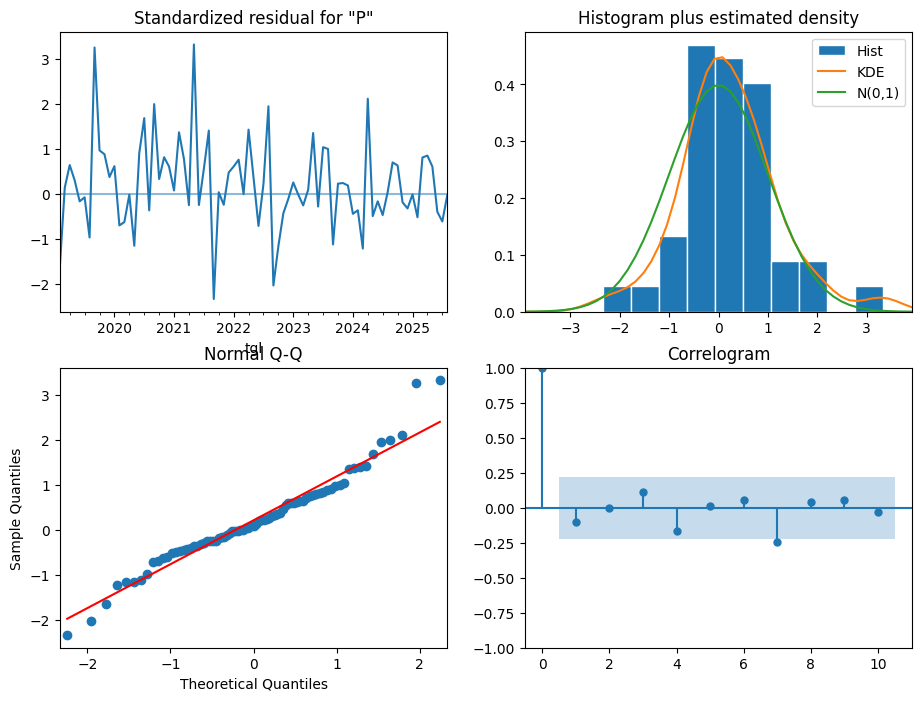

MAPE SARIMAX dua tahap: 13.942766507398478
MAPE ramalan X1       : 14.43560012337414
                                     SARIMAX Results                                      
Dep. Variable:                      Produksi Padi   No. Observations:                   92
Model:             SARIMAX(1, 0, 1)x(0, 1, 1, 12)   Log Likelihood                  69.761
Date:                            Wed, 14 Oct 2026   AIC                           -129.521
Time:                                    13:55:27   BIC                           -117.611
Sample:                                01-01-2018   HQIC                          -124.746
                                     - 08-01-2025                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
X1             5.2844      0.

In [21]:
# 1. cari sisaan ekstrem (13 observasi awal dibuang karena diferensiasi d + 12)
r = m1.resid.iloc[13:]
z = (r - r.mean()) / r.std()
print(z[abs(z) > 2.5])
m1.plot_diagnostics(figsize=(11, 8)); plt.show()

# 2. peramalan dua tahap: ramal X1 dulu, lalu dipakai sebagai exog (lebih realistis)
mx = SARIMAX(Xs.iloc[:, 0], order=(1,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
X_hat = mx.forecast(H_TEST)
pred2 = m1.get_forecast(H_TEST, exog=X_hat.to_frame("X1")).predicted_mean
print("MAPE SARIMAX dua tahap:", mape(yt, pred2))
print("MAPE ramalan X1       :", mape(Xt.iloc[:, 0], X_hat))

# 3. lihat ringkasan model d=0 untuk membandingkan MA(1)-nya
print(m2.summary())

Akurasi

MAPE SARIMAX dua tahap = 13,94%, sedikit lebih baik daripada MAPE ramalan X1 = 14,44%. Dengan MAPE sekitar 14%, akurasi tergolong baik (rentang 10-20%), tetapi belum sangat tinggi.
Selisihnya tipis (sekitar 0,5 poin), jadi keunggulan pendekatan dua tahap tidak besar.

Signifikansi parameter

X1 (koef 5,2844, p = 0,000): signifikan. Variabel ini sangat berpengaruh terhadap produksi padi. Nilai koefisiennya besar, kemungkinan karena data ditransformasi (log) atau memang skalanya berbeda.
ar.L1 (0,7396, p = 0,000): signifikan. Ada ketergantungan kuat pada nilai bulan sebelumnya.
ma.L1 (-0,3197, p = 0,204): tidak signifikan. Komponen MA non-musiman ini bisa dipertimbangkan untuk dibuang, lalu model diuji ulang, misalnya SARIMAX(1,0,0)x(0,1,1,12).
ma.S.L12 (-0,5773, p = 0,000): signifikan. Komponen MA musiman 12 bulan bekerja dengan baik, sesuai pola musiman tanam padi.
sigma2 (0,0096): varians error kecil, yang konsisten dengan data yang kemungkinan sudah di-log.

Diagnostik residual

Ljung-Box (Prob(Q) = 0,97 > 0,05): residual tidak berautokorelasi, jadi model sudah menangkap pola waktunya. Ini bagus.
Jarque-Bera (Prob(JB) = 0,11 > 0,05): residual berdistribusi normal. Skew 0,25 dan kurtosis 4,03 sedikit leptokurtik, tetapi masih dapat diterima.
Heteroskedastisitas (Prob(H) = 0,07 > 0,05): varians residual homogen, tetapi nilainya mendekati batas 0,05 sehingga perlu dicermati.

Kriteria informasi
AIC = -129,521, BIC = -117,611, dan HQIC = -124,746. Nilai ini baru berguna untuk membandingkan dengan model kandidat lain (semakin kecil semakin baik).

Catatan

Peringatan “outer product of gradients” adalah hal standar untuk covariance type opg dan bukan error.
Karena model memakai X1 yang harus diramalkan dulu (tahap pertama), galat ramalan X1 (MAPE 14,4%) ikut merambat ke ramalan padi. Ini alasan MAPE akhir tidak jauh lebih baik.

Kesimpulan: model sudah memenuhi asumsi residual (white noise, normal, homogen) dan akurasinya cukup baik. Satu-satunya kelemahan adalah ma.L1 yang tidak signifikan. Saran saya, coba model tanpa ma.L1 dan bandingkan AIC/BIC serta MAPE-nya.